# next-moe 0.2B + 0.1B Engram: следующий UK/EN эксперимент

Самостоятельный notebook, исходники встроены. Полный профиль: **293.69M параметров**, 12×512,
16 routed / top-2 + shared, GR×4, один Engram, GDN/full GQA 3:1 и pairwise shared KV.

**Runtime → Change runtime type → GPU.** На T4 по умолчанию FP16 веса/градиенты модели,
FP32 master weights и Adam moments, autocast + GradScaler. BF16 — для поддерживающих GPU.
Это безопасная mixed precision схема, а не FP16 Adam целиком. Она не обещает двукратной экономии
всей VRAM: master weights и transient FP32 optimizer gradients также занимают память.

План по умолчанию **10 млн processed tokens**, около 19 532 updates при batch 512 tokens,
по **1000 updates за сессию**. Это следующий эксперимент, не законченный pretraining или SFT.
По пользовательскому тесту 300 updates заняли 25.11 минуты: без ускорения 10M tokens ≈27.25 часа.
Сначала проверьте 20–50 updates нового FP16 режима, затем продолжайте до session limit.

Корпус — открытый [wikimedia/wikipedia](https://huggingface.co/datasets/wikimedia/wikipedia),
configs `20231101.uk/en`, pinned revision. До 10 000 документов и 30M Unicode characters на язык.
Для продолжения предыдущего run BPE и validation сохраняются. После перезапуска Colab нельзя
переобучать tokenizer существующей модели. Учитывайте лицензии корпуса при перераспространении.


In [2]:
%pip -q install tokenizers==0.21.4 datasets==3.6.0 matplotlib
import torch, sys, json, gc, time, shutil, math
from pathlib import Path
print('Python:', sys.version.split()[0], 'Torch:', torch.__version__)
assert tuple(map(int, torch.__version__.split('+')[0].split('.')[:2])) >= (2, 6), 'Нужен PyTorch >=2.6.'
print('CUDA:', torch.cuda.is_available())
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(props.name, round(props.total_memory/2**30, 2), 'GiB; BF16:', torch.cuda.is_bf16_supported(including_emulation=False))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 23.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 26.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 70.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 20.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
transformers 5.18.0 requires huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 0.36.2 which is incompatible.
transformers 5.18.0 requires tokenizers<0.24.0,>=0.23.1, but you have tokenizers 0.21.4 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
di

## Бюджет, сессия и диск

В Drive сохраняется **один `weights.pt`**, около 0.55 GiB в FP16 (1.09 GiB при FP32).
При записи временного файла старый snapshot остаётся: пиковый объём двух FP16 snapshots ≈1.10 GiB.
Данные/metadata/source тоже входят в бюджет run **4.5 GiB**; это заданный лимит одного каталога,
а не проверка реальной свободной квоты Google Drive. Укажите лимит меньше доступного места.
Старые `last.pt` (3.28 GiB) и `model.pt` (1.09 GiB) предыдущего run сами не удаляются. Если они
уже заняли доступное место, освободите/скачайте старые файлы после проверки нового снимка весов.

При USE_DRIVE=False снимок весов тоже остаётся в /content и исчезает при потере runtime.
Полный optimizer checkpoint сохраняется **локально в /content**, не в Drive. После потери runtime
Drive snapshot требует **warm restart**: веса/step/tokens сохраняются, optimizer/master precision/RNG
начинаются заново, LR плавно нарастает 100 updates. Это не точное продолжение.
Пока local `last.pt` доступен, auto использует exact resume с optimizer/RNG. Для точного resume
после потери runtime понадобится отдельно хранить full checkpoint (FP16+master ≈3.83 GiB;
с временной копией ≈7.66 GiB). Вторая копия inference model по умолчанию не создаётся.


In [3]:
PROFILE = 'full'               # tiny только для correctness tests
USE_DRIVE = True
RUN_NAME = 'next-moe-0p2b-engram0p1b-10m-v2'
TOTAL_TOKENS = 10_000_000      # включает tokens предыдущего checkpoint
SESSION_UPDATES = 1000        # сначала можно поставить 20 или 50
STEPS_OVERRIDE = None         # только debugging; обычно None
SEQ_LEN = 512
MICROBATCH = 4
GRAD_ACCUM = 1
PRECISION = 'auto_master'     # auto: fp16_master T4, bf16_master supported GPUs, fp32 CPU
OPTIMIZER = 'adamw'           # optional adamw8bit; не меняйте optimizer при exact resume
CHECKPOINT_BLOCKS = False
DOCUMENTS_PER_LANGUAGE = 10000
VALIDATION_DOCUMENTS = 128    # при продолжении сохраняем старые 32 вместо новых 128
MAX_CHARACTERS_PER_LANGUAGE = 30_000_000
SOURCE = 'wikipedia'
LOCAL_TEXT_DIR = '/content/my_texts'
SEED = 1234
PERSISTENT_BUDGET_GIB = 4.5   # лимит всего каталога run, включая temporary snapshot
RESUME_MODE = 'auto'         # auto / exact / warm / fresh
INIT_FROM_TEST_RUN = True
INIT_CHECKPOINT = ''         # можно явно указать старый last.pt или новый weights.pt
INIT_TOKENIZER = ''
INIT_METADATA = ''

assert PROFILE in ('full', 'tiny')
if PROFILE == 'full' and not torch.cuda.is_available():
    raise RuntimeError('Для полного профиля включите GPU; CPU предназначен для tiny tests.')
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    STORAGE = Path('/content/drive/MyDrive/next-moe')
else:
    STORAGE = Path('/content/next-moe-artifacts')
RUN_DIR = STORAGE / RUN_NAME
LOCAL_DIR = Path('/content/next-moe-local') / RUN_NAME
DATA_DIR = RUN_DIR / 'data-v2'
CACHE_DIR = LOCAL_DIR / 'data'
CODE_DIR = Path('/content/next-moe-code')
for directory in (RUN_DIR, LOCAL_DIR, CODE_DIR): directory.mkdir(parents=True, exist_ok=True)
OLD_RUN = STORAGE / 'next-moe-0p2b-engram0p1b-test-v1'
if RESUME_MODE != 'fresh' and INIT_FROM_TEST_RUN and not INIT_CHECKPOINT and (OLD_RUN / 'last.pt').exists():
    INIT_CHECKPOINT = str(OLD_RUN / 'last.pt')
    INIT_TOKENIZER = str(OLD_RUN / 'tokenizer.json')
    INIT_METADATA = str(OLD_RUN / 'data/metadata.json')
if RESUME_MODE == 'auto':
    if (LOCAL_DIR / 'last.pt').exists():
        resume_path, restore_mode = LOCAL_DIR / 'last.pt', 'exact'
    elif (RUN_DIR / 'weights.pt').exists():
        resume_path, restore_mode = RUN_DIR / 'weights.pt', 'warm'
    elif INIT_CHECKPOINT:
        resume_path, restore_mode = Path(INIT_CHECKPOINT), 'warm'
    else:
        resume_path, restore_mode = None, 'fresh'
elif RESUME_MODE in ('exact', 'warm'):
    resume_path = Path(INIT_CHECKPOINT) if INIT_CHECKPOINT else (
        LOCAL_DIR / 'last.pt' if RESUME_MODE == 'exact' else RUN_DIR / 'weights.pt')
    restore_mode = RESUME_MODE
elif RESUME_MODE == 'fresh':
    if (RUN_DIR / 'weights.pt').exists() or (LOCAL_DIR / 'last.pt').exists():
        raise RuntimeError('Для fresh запуска с новыми весами используйте новое RUN_NAME.')
    resume_path, restore_mode = None, 'fresh'
else:
    raise ValueError(RESUME_MODE)
if resume_path is not None and not resume_path.exists(): raise FileNotFoundError(resume_path)
if OPTIMIZER == 'adamw8bit':
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'bitsandbytes==0.45.5'])
print('Restore mode:', restore_mode, 'checkpoint:', resume_path)


Mounted at /content/drive
Restore mode: warm checkpoint: /content/drive/MyDrive/next-moe/next-moe-0p2b-engram0p1b-10m-v2/weights.pt


## Встроенные исходники

Reference PyTorch kernels: triangular GDN FP32, no-drop MoE, GR, Engram, SDPA.
FlashAttention backend зависит от GPU/dtype. FP32 master optimizer использует FP32 gradients после
копирования scaled gradients модели; GradScaler не выполняет unscale_ на FP16 tensors.
Persistent KV/GDN decode API и production Triton/fused MoE ещё не реализованы.


In [4]:
SOURCES = {'next_moe/__init__.py': '"""Experimental, trainable next-moe reference implementation."""\nfrom .model import ModelConfig, NextMoE\n', 'next_moe/data.py': '"""Bounded UK/EN document ingestion, leak-free split, tokenizer and token files."""\nfrom pathlib import Path\nimport hashlib\nimport json\nimport numpy as np\nfrom tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders\n\nLANGUAGES = (\'uk\', \'en\')\nSPECIAL = [\'<pad>\', \'<bos>\', \'<eos>\', \'<unk>\']\nWIKIPEDIA_REVISION = \'b04c8d1ceb2f5cd4588862100d08de323dccfbaa\'\n\n\ndef document_sources(source=\'wikipedia\', local_dir=None):\n    if source == \'wikipedia\':\n        from datasets import load_dataset\n        # Public parquet dataset. No trust_remote_code; no full-dataset download.\n        return {lang: iter(load_dataset(\n            \'wikimedia/wikipedia\', f\'20231101.{lang}\', revision=WIKIPEDIA_REVISION,\n            split=\'train\', streaming=True))\n                for lang in LANGUAGES}\n    if source != \'local\' or local_dir is None:\n        raise ValueError(\'Use wikipedia or local with a directory containing uk/ and en/.\')\n    result = {}\n    for lang in LANGUAGES:\n        paths = sorted((Path(local_dir) / lang).glob(\'*.txt\'))\n        if len(paths) < 2:\n            raise ValueError(f\'Need at least two separate UTF-8 documents in {lang}/.\')\n        result[lang] = ({\'text\': path.read_text(encoding=\'utf-8\'), \'id\': path.name,\n                         \'url\': None, \'title\': path.name} for path in paths)\n    return result\n\n\ndef prepare_data(output, source=\'wikipedia\', local_dir=None, documents_per_language=1000,\n                 validation_documents=32, vocab_size=65536, max_chars_per_document=20000,\n                 seed=1234, tokenizer_path=None, fixed_validation_metadata=None,\n                 max_characters_per_language=None):\n    if documents_per_language <= validation_documents or validation_documents < 1:\n        raise ValueError(\'Training and validation must both contain documents.\')\n    output = Path(output)\n    output.mkdir(parents=True, exist_ok=True)\n    old = (json.loads(Path(fixed_validation_metadata).read_text())\n           if fixed_validation_metadata is not None else None)\n    if old and tokenizer_path is None:\n        raise ValueError(\'Preserving old validation requires its original tokenizer.\')\n    reserved_owner = ({digest: lang for lang in LANGUAGES for digest in old[\'document_hashes\'][lang][\'val\']}\n                      if old else {})\n    raw = document_sources(source, local_dir)\n    documents, seen, hashes, provenance, scanned, used_characters = {}, set(), {}, {}, {}, {}\n    for lang in LANGUAGES:\n        reserved = set(old[\'document_hashes\'][lang][\'val\']) if old else set()\n        docs, ids, origins = [], [], []\n        scanned[lang], used_characters[lang] = 0, 0\n        for record in raw[lang]:\n            scanned[lang] += 1\n            text = record[\'text\'].strip()\n            if len(text) < 200:\n                continue\n            full_digest = hashlib.sha256(text.encode(\'utf-8\')).hexdigest()\n            text = text[:max_chars_per_document]\n            digest = hashlib.sha256(text.encode(\'utf-8\')).hexdigest()\n            if digest in seen or (digest in reserved_owner and reserved_owner[digest] != lang):\n                continue\n            if max_characters_per_language is not None and used_characters[lang] + len(text) > max_characters_per_language:\n                break\n            seen.add(digest)\n            docs.append(text)\n            ids.append(digest)\n            used_characters[lang] += len(text)\n            origins.append({\'id\': record.get(\'id\'), \'url\': record.get(\'url\'),\n                            \'title\': record.get(\'title\'), \'sha256_used_text\': digest,\n                            \'sha256_full_stripped_text\': full_digest, \'used_characters\': len(text)})\n            if len(docs) >= documents_per_language and reserved.issubset(set(ids)):\n                break\n        if old:\n            if not reserved.issubset(set(ids)):\n                raise ValueError(f\'Cannot recover all original {lang} validation documents; \'\n                                 \'increase corpus limits and keep source/truncation unchanged.\')\n            val = [ids.index(h) for h in old[\'document_hashes\'][lang][\'val\']]\n            train = [i for i, h in enumerate(ids) if h not in reserved]\n        else:\n            if len(docs) < validation_documents + 1:\n                raise ValueError(f\'Too few usable {lang} documents ({len(docs)}).\')\n            order = np.random.default_rng(seed).permutation(len(docs))\n            val, train = list(order[:validation_documents]), list(order[validation_documents:])\n        if not train:\n            raise ValueError(f\'No training documents for {lang}.\')\n        documents[lang], hashes[lang], provenance[lang] = {}, {}, {}\n        for split, indices in [(\'val\', val), (\'train\', train)]:\n            documents[lang][split] = [docs[i] for i in indices]\n            hashes[lang][split] = [ids[i] for i in indices]\n            provenance[lang][split] = [origins[i] for i in indices]\n    if tokenizer_path is not None:\n        tokenizer = Tokenizer.from_file(str(tokenizer_path))\n        if tokenizer.get_vocab_size() > vocab_size:\n            raise ValueError(\'Existing tokenizer exceeds model vocabulary.\')\n        import shutil\n        shutil.copy2(tokenizer_path, output / \'tokenizer.json\')  # exact bytes, unchanged IDs\n    else:\n        tokenizer = Tokenizer(models.BPE(unk_token=\'<unk>\'))\n        tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)\n        tokenizer.decoder = decoders.ByteLevel()\n        trainer = trainers.BpeTrainer(vocab_size=vocab_size, min_frequency=2, special_tokens=SPECIAL,\n                                      initial_alphabet=pre_tokenizers.ByteLevel.alphabet())\n        tokenizer.train_from_iterator((doc for lang in LANGUAGES for doc in documents[lang][\'train\']),\n                                      trainer=trainer)\n        tokenizer.save(str(output / \'tokenizer.json\'))\n    metadata = {\'source\': source, \'source_config\': \'20231101.{uk,en}\' if source == \'wikipedia\' else None,\n                \'source_dataset\': \'wikimedia/wikipedia\' if source == \'wikipedia\' else None,\n                \'source_revision\': WIKIPEDIA_REVISION if source == \'wikipedia\' else None,\n                \'requested_documents_per_language\': documents_per_language,\n                \'requested_validation_documents_per_language\': validation_documents,\n                \'validation_documents_per_language\': len(documents[\'uk\'][\'val\']) if len(documents[\'uk\'][\'val\']) == len(documents[\'en\'][\'val\']) else None,\n                \'max_characters_per_document\': max_chars_per_document,\n                \'max_characters_per_language\': max_characters_per_language,\n                \'used_characters\': used_characters,\n                \'min_characters_per_document\': 200, \'scanned_documents\': scanned,\n                \'document_counts\': {lang: {split: len(documents[lang][split])\n                                          for split in (\'train\', \'val\')} for lang in LANGUAGES},\n                \'seed\': seed, \'document_hashes\': hashes, \'requested_vocab\': vocab_size,\n                \'actual_vocab\': tokenizer.get_vocab_size(), \'normalization\': \'none; byte-level BPE\',\n                \'tokenizer_reused\': tokenizer_path is not None,\n                \'validation_preserved\': old is not None,\n                \'special_ids\': {s: tokenizer.token_to_id(s) for s in SPECIAL}, \'tokens\': {}}\n    for lang in LANGUAGES:\n        for split in (\'train\', \'val\'):\n            count = 0\n            with (output / f\'{split}_{lang}.bin\').open(\'wb\') as handle:\n                for doc in documents[lang][split]:\n                    ids = tokenizer.encode(doc).ids + [tokenizer.token_to_id(\'<eos>\')]\n                    np.asarray(ids, dtype=np.int32).tofile(handle)\n                    count += len(ids)\n            metadata[\'tokens\'][f\'{split}_{lang}\'] = count\n    (output / \'documents.json\').write_text(json.dumps(provenance, ensure_ascii=False, indent=2))\n    (output / \'metadata.json\').write_text(json.dumps(metadata, ensure_ascii=False, indent=2))\n    print(json.dumps({key: metadata[key] for key in (\'document_counts\', \'actual_vocab\', \'tokens\', \'special_ids\')}, indent=2))\n    return metadata\n\n\nclass TokenBatches:\n    """50/50 UK/EN sampling, no padding; CPU RNG state is checkpointed."""\n    def __init__(self, folder, sequence_length=128, microbatch=1, seed=1234):\n        import torch\n        self.torch = torch\n        self.length, self.batch = sequence_length, microbatch\n        self.rng = torch.Generator().manual_seed(seed)\n        self.arrays = {(split, lang): np.memmap(Path(folder) / f\'{split}_{lang}.bin\',\n                                              mode=\'r\', dtype=np.int32)\n                       for split in (\'train\', \'val\') for lang in LANGUAGES}\n        for key, array in self.arrays.items():\n            if len(array) <= sequence_length:\n                raise ValueError(f\'{key} needs more than {sequence_length} tokens.\')\n\n    def get(self, split, device, language=None, generator=None):\n        torch = self.torch\n        gen = self.rng if generator is None else generator\n        xs, ys = [], []\n        for _ in range(self.batch):\n            lang = language or LANGUAGES[int(torch.randint(2, (1,), generator=gen))]\n            array = self.arrays[(split, lang)]\n            start = int(torch.randint(len(array) - self.length, (1,), generator=gen))\n            row = torch.from_numpy(np.array(array[start:start + self.length + 1], dtype=np.int64))\n            xs.append(row[:-1]); ys.append(row[1:])\n        return torch.stack(xs).to(device), torch.stack(ys).to(device)\n', 'next_moe/model.py': '"""Trainable v0.3 reference: GR + causal Engram + GDN/GQA + no-drop MoE.\n\nThe chunkwise GDN is an exact triangular reformulation of the recurrence,\nnot a production Triton kernel. Generation recomputes the prefix (no KV API).\n"""\nfrom dataclasses import asdict, dataclass, field\nimport math\nimport torch\nfrom torch import nn\nfrom torch.nn import functional as F\nfrom torch.utils.checkpoint import checkpoint\n\n\n@dataclass\nclass ModelConfig:\n    vocab_size: int = 65536\n    layers: int = 12\n    dim: int = 512\n    experts: int = 16\n    top_k: int = 2\n    expert_dim: int = 448\n    branches: int = 4\n    rank: int = 64\n    q_heads: int = 8\n    kv_heads: int = 2\n    head_dim: int = 64\n    gdn_k_heads: int = 4\n    gdn_v_heads: int = 8\n    gdn_key_dim: int = 64\n    gdn_value_dim: int = 64\n    table_rows: list[int] = field(default_factory=lambda: [390647, 390653, 390671, 390673,\n                                                          390703, 390707, 390721, 390727])\n    row_dim: int = 32\n    full_every: int = 4\n    kv_group: int = 2\n    memory_layer: int = 1  # zero-based: decoder block 2\n    gdn_chunk: int = 32\n    rope_theta: float = 10000.0\n    eos_id: int = 2\n    pad_id: int = 0\n    checkpoint_blocks: bool = True\n\n    def __post_init__(self):\n        if self.layers % self.full_every or not 0 <= self.memory_layer < self.layers:\n            raise ValueError(\'Layers must end with a full layer; memory layer must exist.\')\n        if self.q_heads % self.kv_heads or self.gdn_v_heads % self.gdn_k_heads:\n            raise ValueError(\'Head ratios must be integral.\')\n        if not 1 <= self.top_k <= self.experts or len(self.table_rows) != 8:\n            raise ValueError(\'Invalid expert or Engram configuration.\')\n        if self.kv_group != 2 or self.head_dim % 2 or self.gdn_chunk < 1:\n            raise ValueError(\'This reference supports KV pairs and even RoPE dimensions.\')\n\n    @classmethod\n    def tiny(cls):\n        """Only for correctness tests; not the 0.2B+0.1B profile."""\n        return cls(vocab_size=512, layers=8, dim=32, experts=4, top_k=2,\n                   expert_dim=24, rank=4, q_heads=4, kv_heads=2, head_dim=8,\n                   gdn_k_heads=2, gdn_v_heads=4, gdn_key_dim=8, gdn_value_dim=8,\n                   table_rows=[101, 103, 107, 109, 113, 127, 131, 137], row_dim=4,\n                   gdn_chunk=4)\n\n    def to_dict(self):\n        return asdict(self)\n\n\nclass RMSNorm(nn.Module):\n    def __init__(self, shape, eps=1e-6):\n        super().__init__()\n        self.weight = nn.Parameter(torch.ones(shape))\n        self.eps = eps\n\n    def forward(self, x):\n        y = x.float() * torch.rsqrt(x.float().square().mean(-1, keepdim=True) + self.eps)\n        return (y * self.weight.float()).to(x.dtype)\n\n\nclass GatedResidual(nn.Module):\n    def __init__(self, cfg, write=True):\n        super().__init__()\n        self.n, self.d = cfg.branches, cfg.dim\n        self.norm = RMSNorm((self.n, self.d))\n        self.down = nn.Linear(self.n * self.d, cfg.rank, bias=False)\n        self.up = nn.Linear(cfg.rank, self.n * self.d, bias=False)\n        self.write = nn.Linear(self.n * self.d, self.n, bias=False) if write else None\n\n    def read(self, r):\n        normalized = self.norm(r)\n        z = normalized.flatten(-2)\n        gate = self.up(F.silu(self.down(z) / self.n)).sigmoid().reshape_as(r)\n        x = (gate * normalized).mean(-2)\n        s = 2 * (self.write(z) / self.n).sigmoid() if self.write is not None else None\n        return x, s\n\n    @staticmethod\n    def add(r, y, s):\n        return r + s.unsqueeze(-1).to(r.dtype) * y.unsqueeze(-2).to(r.dtype)\n\n\nclass CausalConv(nn.Module):\n    def __init__(self, width, kernel=4, dilation=1):\n        super().__init__()\n        self.left = (kernel - 1) * dilation\n        self.conv = nn.Conv1d(width, width, kernel, groups=width,\n                              dilation=dilation, bias=False)\n\n    def forward(self, x):\n        return self.conv(F.pad(x.transpose(1, 2), (self.left, 0))).transpose(1, 2)\n\n\nclass Engram(nn.Module):\n    def __init__(self, cfg):\n        super().__init__()\n        self.cfg = cfg\n        self.tables = nn.ModuleList([nn.Embedding(rows, cfg.row_dim) for rows in cfg.table_rows])\n        m, n, d = 8 * cfg.row_dim, cfg.branches, cfg.dim\n        self.value = nn.Linear(m, d, bias=False)\n        self.key = nn.Linear(m, n * d, bias=False)\n        self.query_norm, self.key_norm, self.conv_norm = [RMSNorm((n, d)) for _ in range(3)]\n        self.conv = CausalConv(n * d, kernel=4, dilation=3)\n\n    def addresses(self, tokens):\n        # Token IDs are kept unchanged: no accent stripping or case folding.\n        # Reset suffix lookup at EOS; left padding is deterministic at sample starts.\n        lag1 = F.pad(tokens[:, :-1], (1, 0), value=self.cfg.pad_id)\n        lag2 = F.pad(tokens[:, :-2], (2, 0), value=self.cfg.pad_id)[:, :tokens.shape[1]]\n        reset = tokens.eq(self.cfg.eos_id) | lag1.eq(self.cfg.eos_id)\n        lag1 = torch.where(reset, self.cfg.pad_id, lag1)\n        lag2 = torch.where(reset | lag2.eq(self.cfg.eos_id), self.cfg.pad_id, lag2)\n        hashes = []\n        for i, rows in enumerate(self.cfg.table_rows):\n            # Small integer coefficients keep arithmetic far below int64 overflow.\n            code = (tokens + 1) * (1009 + 104 * i) + (lag1 + 1) * (9176 + 62 * i)\n            if i >= 4:\n                code = code + (lag2 + 1) * (65537 + 50 * i)\n            hashes.append(code.remainder(rows))\n        return hashes\n\n    def forward(self, tokens, r):\n        e = torch.cat([table(ids) for table, ids in zip(self.tables, self.addresses(tokens))], -1)\n        e = e.to(r.dtype)\n        v = self.value(e)\n        key = self.key(e).reshape_as(r)\n        score = (self.query_norm(r).float() * self.key_norm(key).float()).sum(-1) / math.sqrt(self.cfg.dim)\n        transformed = score.sign() * score.abs().clamp_min(1e-6).sqrt()\n        u = transformed.sigmoid().unsqueeze(-1).to(r.dtype) * v.unsqueeze(-2)\n        conv = self.conv(self.conv_norm(u).flatten(-2)).reshape_as(r)\n        return r + u.to(r.dtype) + F.silu(conv).to(r.dtype)\n\n\ndef delta_chunk(q, k, v, log_alpha, beta, state):\n    """Exact gated-delta recurrence within one chunk. Shapes B,H,T,D; state B,H,K,V.\n\n    Solve write residuals against a unit-lower-triangular matrix. FP32 avoids\n    accumulation loss; no attention across future positions is performed.\n    """\n    with torch.autocast(device_type=q.device.type, enabled=False):\n        q, k, v, log_alpha, beta, state = [x.float() for x in (q, k, v, log_alpha, beta, state)]\n        length = q.shape[-2]\n        cumulative = log_alpha.cumsum(-1)\n        decay = cumulative.exp()\n        ratios = (cumulative.unsqueeze(-1) - cumulative.unsqueeze(-2)).clamp_max(0).exp()\n        kk = k @ k.transpose(-1, -2)\n        lower = (ratios * kk * beta.unsqueeze(-2)).tril(-1)\n        matrix = lower + torch.eye(length, device=q.device, dtype=torch.float32)\n        rhs = v - decay.unsqueeze(-1) * (k @ state)\n        errors = torch.linalg.solve_triangular(matrix, rhs, upper=False, unitriangular=True)\n        weights = (ratios * (q @ k.transpose(-1, -2)) * beta.unsqueeze(-2)).tril()\n        y = decay.unsqueeze(-1) * (q @ state) + weights @ errors\n        last_ratios = (cumulative[..., -1:] - cumulative).exp()\n        next_state = decay[..., -1, None, None] * state + k.transpose(-1, -2) @ (\n            errors * (last_ratios * beta).unsqueeze(-1))\n        return y, next_state\n\n\nclass GDN(nn.Module):\n    def __init__(self, cfg):\n        super().__init__()\n        self.cfg = cfg\n        k = cfg.gdn_k_heads * cfg.gdn_key_dim\n        w = cfg.gdn_v_heads * cfg.gdn_value_dim\n        self.qkv = nn.Linear(cfg.dim, 2 * k + w, bias=False)\n        self.conv = CausalConv(2 * k + w)\n        self.decay = nn.Linear(cfg.dim, cfg.gdn_v_heads, bias=False)\n        self.beta = nn.Linear(cfg.dim, cfg.gdn_v_heads, bias=False)\n        self.gate = nn.Linear(cfg.dim, w, bias=False)\n        self.out = nn.Linear(w, cfg.dim, bias=False)\n        self.norm = RMSNorm(cfg.gdn_value_dim)\n        self.A_log = nn.Parameter(torch.linspace(0, math.log(16), cfg.gdn_v_heads))\n        # Initial update time constants in [0.001, 0.1].\n        dt = torch.exp(torch.linspace(math.log(.001), math.log(.1), cfg.gdn_v_heads))\n        self.dt_bias = nn.Parameter(torch.log(torch.expm1(dt)))\n\n    def forward(self, x):\n        c = self.cfg\n        b, t, _ = x.shape\n        kw, vw = c.gdn_k_heads * c.gdn_key_dim, c.gdn_v_heads * c.gdn_value_dim\n        q, k, v = F.silu(self.conv(self.qkv(x))).split([kw, kw, vw], -1)\n        repeat = c.gdn_v_heads // c.gdn_k_heads\n        q = q.reshape(b, t, c.gdn_k_heads, c.gdn_key_dim).repeat_interleave(repeat, dim=2).transpose(1, 2)\n        k = k.reshape(b, t, c.gdn_k_heads, c.gdn_key_dim).repeat_interleave(repeat, dim=2).transpose(1, 2)\n        q, k = F.normalize(q.float(), dim=-1, eps=1e-6), F.normalize(k.float(), dim=-1, eps=1e-6)\n        v = v.reshape(b, t, c.gdn_v_heads, c.gdn_value_dim).transpose(1, 2)\n        log_alpha = -F.softplus(self.decay(x).float() + self.dt_bias.float()) * self.A_log.float().exp()\n        log_alpha = log_alpha.transpose(1, 2)\n        beta = self.beta(x).float().sigmoid().transpose(1, 2)\n        state = torch.zeros(b, c.gdn_v_heads, c.gdn_key_dim, c.gdn_value_dim, device=x.device)\n        outputs = []\n        for start in range(0, t, c.gdn_chunk):\n            stop = min(start + c.gdn_chunk, t)\n            y, state = delta_chunk(q[:, :, start:stop], k[:, :, start:stop], v[:, :, start:stop],\n                                  log_alpha[:, :, start:stop], beta[:, :, start:stop], state)\n            outputs.append(y)\n        y = torch.cat(outputs, dim=2).transpose(1, 2).to(x.dtype)\n        y = self.norm(y).reshape(b, t, vw) * self.gate(x).sigmoid()\n        return self.out(y)\n\n\ndef rope(x, theta):\n    t, d = x.shape[-2:]\n    positions = torch.arange(t, device=x.device).float()\n    inverse = theta ** (-torch.arange(0, d, 2, device=x.device).float() / d)\n    angle = positions[:, None] * inverse[None, :]\n    cos, sin = angle.cos().to(x.dtype), angle.sin().to(x.dtype)\n    left, right = x[..., :d // 2], x[..., d // 2:]\n    return torch.cat([left * cos - right * sin, right * cos + left * sin], -1)\n\n\nclass GQA(nn.Module):\n    def __init__(self, cfg, owner):\n        super().__init__()\n        self.cfg, self.owner = cfg, owner\n        self.q = nn.Linear(cfg.dim, cfg.q_heads * cfg.head_dim, bias=False)\n        self.gate = nn.Linear(cfg.dim, cfg.q_heads * cfg.head_dim, bias=False)\n        self.out = nn.Linear(cfg.q_heads * cfg.head_dim, cfg.dim, bias=False)\n        self.q_norm = RMSNorm(cfg.head_dim)\n        self.k_norm = RMSNorm(cfg.head_dim) if owner else None\n        self.k = nn.Linear(cfg.dim, cfg.kv_heads * cfg.head_dim, bias=False) if owner else None\n        self.v = nn.Linear(cfg.dim, cfg.kv_heads * cfg.head_dim, bias=False) if owner else None\n\n    def forward(self, x, kv=None):\n        c = self.cfg\n        b, t, _ = x.shape\n        q = rope(self.q_norm(self.q(x).reshape(b, t, c.q_heads, c.head_dim)).transpose(1, 2), c.rope_theta)\n        if self.owner:\n            k = rope(self.k_norm(self.k(x).reshape(b, t, c.kv_heads, c.head_dim)).transpose(1, 2), c.rope_theta)\n            v = self.v(x).reshape(b, t, c.kv_heads, c.head_dim).transpose(1, 2)\n            kv = (k, v)\n        if kv is None:\n            raise ValueError(\'KV reader requires source tensors.\')\n        # Explicit repeat is portable to Colab SDPA backends; logical KV stays shared.\n        k, v = [z.repeat_interleave(c.q_heads // c.kv_heads, dim=1) for z in kv]\n        y = F.scaled_dot_product_attention(q, k, v, is_causal=True, dropout_p=0.0)\n        y = y.transpose(1, 2).reshape(b, t, c.q_heads * c.head_dim)\n        return self.out(y * self.gate(x).sigmoid()), kv\n\n\nclass Expert(nn.Module):\n    def __init__(self, dim, hidden):\n        super().__init__()\n        self.gate = nn.Linear(dim, hidden, bias=False)\n        self.up = nn.Linear(dim, hidden, bias=False)\n        self.down = nn.Linear(hidden, dim, bias=False)\n\n    def forward(self, x):\n        return self.down(F.silu(self.gate(x)) * self.up(x))\n\n\nclass MoE(nn.Module):\n    def __init__(self, cfg):\n        super().__init__()\n        self.cfg = cfg\n        self.router = nn.Linear(cfg.dim, cfg.experts, bias=False)\n        self.experts = nn.ModuleList([Expert(cfg.dim, cfg.expert_dim) for _ in range(cfg.experts)])\n        self.shared = Expert(cfg.dim, cfg.expert_dim)\n\n    def forward(self, x):\n        shape = x.shape\n        flat = x.reshape(-1, self.cfg.dim)\n        with torch.autocast(device_type=x.device.type, enabled=False):\n            probabilities = F.linear(flat.float(), self.router.weight.float()).softmax(-1)\n        weights, selected = probabilities.topk(self.cfg.top_k, dim=-1)\n        weights = weights / weights.sum(-1, keepdim=True)\n        y = torch.zeros_like(flat)\n        for idx, expert in enumerate(self.experts):\n            token, slot = torch.where(selected == idx)\n            if token.numel():\n                out = expert(flat[token]) * weights[token, slot, None].to(x.dtype)\n                y = y.index_add(0, token, out.to(y.dtype))\n        counts = torch.bincount(selected.flatten(), minlength=self.cfg.experts).float()\n        fraction = counts / selected.numel()\n        auxiliary = self.cfg.experts * (fraction.detach() * probabilities.mean(0)).sum()\n        return (y + self.shared(flat)).reshape(shape), auxiliary, counts.detach()\n\n\nclass Block(nn.Module):\n    def __init__(self, cfg, index):\n        super().__init__()\n        self.full = (index + 1) % cfg.full_every == 0\n        self.owner = self.full and ((index + 1) // cfg.full_every - 1) % cfg.kv_group == 0\n        self.memory = Engram(cfg) if index == cfg.memory_layer else None\n        self.attn_gr, self.moe_gr = GatedResidual(cfg), GatedResidual(cfg)\n        self.mixer = GQA(cfg, self.owner) if self.full else GDN(cfg)\n        self.moe = MoE(cfg)\n\n    def forward(self, r, tokens, kv):\n        if self.memory is not None:\n            r = self.memory(tokens, r)\n        x, s = self.attn_gr.read(r)\n        if self.full:\n            y, kv = self.mixer(x, kv)\n        else:\n            y = self.mixer(x)\n        r = self.attn_gr.add(r, y, s)\n        x, s = self.moe_gr.read(r)\n        y, aux, counts = self.moe(x)\n        return self.moe_gr.add(r, y, s), kv, aux, counts\n\n\nclass NextMoE(nn.Module):\n    def __init__(self, cfg):\n        super().__init__()\n        self.config = cfg\n        self.embedding = nn.Embedding(cfg.vocab_size, cfg.dim)\n        self.blocks = nn.ModuleList([Block(cfg, i) for i in range(cfg.layers)])\n        self.final_gr = GatedResidual(cfg, write=False)\n        self.apply(self._init)\n        # Zero initial write projections => scalar write 1. Small mixer outputs\n        # keep a newly initialized multi-stream residual stable.\n        for block in self.blocks:\n            nn.init.zeros_(block.attn_gr.write.weight)\n            nn.init.zeros_(block.moe_gr.write.weight)\n            nn.init.normal_(block.mixer.out.weight, std=.02 / math.sqrt(2 * cfg.layers))\n        self.last_counts = None\n\n    @staticmethod\n    def _init(module):\n        if isinstance(module, (nn.Linear, nn.Embedding)):\n            nn.init.normal_(module.weight, std=.02)\n\n    def features(self, tokens):\n        r = self.embedding(tokens)\n        if torch.is_autocast_enabled(tokens.device.type):\n            r = r.to(torch.get_autocast_dtype(tokens.device.type))\n        r = r.unsqueeze(-2).expand(-1, -1, self.config.branches, -1).clone()\n        kv, auxiliary, counts = None, [], []\n        for block in self.blocks:\n            if self.training and self.config.checkpoint_blocks and torch.is_grad_enabled():\n                r, kv, aux, count = checkpoint(block, r, tokens, kv, use_reentrant=False)\n            else:\n                r, kv, aux, count = block(r, tokens, kv)\n            auxiliary.append(aux)\n            counts.append(count)\n        self.last_counts = torch.stack(counts)\n        return self.final_gr.read(r)[0], torch.stack(auxiliary).mean()\n\n    def forward(self, tokens, targets=None, loss_chunk=64):\n        hidden, auxiliary = self.features(tokens)\n        if targets is None:\n            return F.linear(hidden, self.embedding.weight)\n        # Chunk and checkpoint the softmax/head to avoid B*T*V live logits.\n        total = hidden.new_zeros((), dtype=torch.float32)\n        for start in range(0, tokens.shape[1], loss_chunk):\n            h = hidden[:, start:start + loss_chunk]\n            y = targets[:, start:start + loss_chunk]\n            def loss_fn(hh, yy):\n                logits = F.linear(hh, self.embedding.weight)\n                return F.cross_entropy(logits.float().reshape(-1, self.config.vocab_size),\n                                       yy.reshape(-1), reduction=\'sum\')\n            loss = checkpoint(loss_fn, h, y, use_reentrant=False) if self.training else loss_fn(h, y)\n            total = total + loss\n        return {\'ce\': total / targets.numel(), \'aux\': auxiliary}\n\n    @torch.no_grad()\n    def generate(self, tokens, max_new_tokens=64, temperature=.8, top_k=40, context=512, valid_vocab=None):\n        was_training = self.training\n        self.eval()\n        try:\n            for _ in range(max_new_tokens):\n                hidden, _ = self.features(tokens[:, -context:])\n                logits = F.linear(hidden[:, -1], self.embedding.weight).float()\n                if valid_vocab is not None:\n                    logits[:, valid_vocab:] = float(\'-inf\')\n                logits[:, self.config.pad_id] = float(\'-inf\')\n                if temperature <= 0:\n                    nxt = logits.argmax(-1, keepdim=True)\n                else:\n                    logits = logits / temperature\n                    threshold = logits.topk(min(top_k, logits.shape[-1]), dim=-1).values[:, -1:]\n                    logits = logits.masked_fill(logits < threshold, float(\'-inf\'))\n                    nxt = torch.multinomial(logits.softmax(-1), 1)\n                tokens = torch.cat([tokens, nxt], -1)\n                if tokens.shape[0] == 1 and nxt.item() == self.config.eos_id:\n                    break\n            return tokens\n        finally:\n            self.train(was_training)\n', 'next_moe/precision.py': '"""FP16/BF16 model parameters with FP32 master weights for stable Adam updates."""\nimport torch\n\n\nclass MasterWeights:\n    def __init__(self, parameters):\n        self.model = list(parameters)\n        self.master = [torch.nn.Parameter(p.detach().float().clone(), requires_grad=p.requires_grad)\n                       for p in self.model]\n\n    def copy_gradients(self):\n        # GradScaler operates on FP32 masters, avoiding unscale_ on FP16 gradients.\n        for model, master in zip(self.model, self.master):\n            master.grad = None if model.grad is None else model.grad.detach().float()\n            model.grad = None  # release low-precision gradients as we convert\n\n    @torch.no_grad()\n    def copy_to_model(self):\n        for model, master in zip(self.model, self.master):\n            model.copy_(master)\n\n    def zero_grad(self):\n        for model in self.model:\n            model.grad = None\n', 'next_moe/train.py': '"""Single-GPU test trainer with autocast, checkpointing, evaluation and resume."""\nfrom contextlib import nullcontext\nfrom dataclasses import asdict, dataclass\nfrom pathlib import Path\nimport hashlib\nimport json\nimport math\nimport os\nimport time\nimport torch\nfrom .data import TokenBatches\nfrom .model import ModelConfig, NextMoE\nfrom .precision import MasterWeights\n\n\n@dataclass\nclass TrainConfig:\n    steps: int = 300  # total optimizer updates, including resumed updates\n    sequence_length: int = 128\n    microbatch: int = 1\n    accumulation: int = 4\n    learning_rate: float = 2e-4\n    warmup: int = 20\n    auxiliary_weight: float = .01\n    weight_decay: float = .1\n    grad_clip: float = 1.0\n    eval_every: int = 50\n    eval_batches: int = 4\n    save_every: int = 100\n    log_every: int = 10\n    optimizer: str = \'adamw\'  # optional \'adamw8bit\'; no CPU offload\n    seed: int = 1234\n    precision: str = \'fp32\'  # fp32 / fp16_master / bf16_master\n    restart_warmup: int = 100\n\n\nclass Trainer:\n    def __init__(self, model_config, train_config, data_dir, output_dir, device=None, resume=None,\n                 resume_mode=\'exact\', resume_tokenizer=None, checkpoint_dir=None,\n                 persistent_weights=False, disk_budget_gib=None):\n        self.cfg, self.model_config = train_config, model_config\n        self.device = torch.device(device or (\'cuda\' if torch.cuda.is_available() else \'cpu\'))\n        if min(train_config.steps, train_config.accumulation, train_config.microbatch,\n               train_config.sequence_length, train_config.eval_batches, train_config.log_every,\n               train_config.eval_every, train_config.save_every) < 1:\n            raise ValueError(\'Step/batch/interval values must be positive.\')\n        if train_config.optimizer not in (\'adamw\', \'adamw8bit\'):\n            raise ValueError(\'Unknown optimizer.\')\n        self.output = Path(output_dir)\n        self.output.mkdir(parents=True, exist_ok=True)\n        self.checkpoint_dir = Path(checkpoint_dir or output_dir)\n        self.checkpoint_dir.mkdir(parents=True, exist_ok=True)\n        self.persistent_weights = persistent_weights\n        self.disk_budget_gib = disk_budget_gib\n        self.log_path = self.checkpoint_dir / \'metrics.jsonl\'\n        import shutil\n        if self.log_path != self.output / \'metrics.jsonl\' and not self.log_path.exists() and (self.output / \'metrics.jsonl\').exists():\n            shutil.copy2(self.output / \'metrics.jsonl\', self.log_path)\n        self.data_dir = Path(data_dir)\n        meta = json.loads((self.data_dir / \'metadata.json\').read_text())\n        if meta[\'actual_vocab\'] > model_config.vocab_size:\n            raise ValueError(\'Tokenizer vocabulary exceeds model embedding size.\')\n        if meta[\'special_ids\'][\'<eos>\'] != model_config.eos_id or meta[\'special_ids\'][\'<pad>\'] != model_config.pad_id:\n            raise ValueError(\'Tokenizer special IDs do not match model configuration.\')\n        self.data_signature = self._data_signature()\n        self.tokenizer_signature = hashlib.sha256((self.data_dir / \'tokenizer.json\').read_bytes()).hexdigest()\n        torch.manual_seed(train_config.seed)\n        if self.device.type == \'cuda\':\n            torch.cuda.manual_seed_all(train_config.seed)\n        self.batches = TokenBatches(data_dir, train_config.sequence_length,\n                                   train_config.microbatch, train_config.seed)\n        if train_config.precision not in (\'fp32\', \'fp16_master\', \'bf16_master\'):\n            raise ValueError(\'Unknown parameter precision.\')\n        self.dtype = (torch.bfloat16 if self.device.type == \'cuda\' and torch.cuda.is_bf16_supported(including_emulation=False)\n                      else torch.float16)\n        parameter_dtype = {\'fp32\': torch.float32, \'fp16_master\': torch.float16,\n                           \'bf16_master\': torch.bfloat16}[train_config.precision]\n        if parameter_dtype == torch.bfloat16 and self.device.type == \'cuda\' and not torch.cuda.is_bf16_supported(including_emulation=False):\n            raise ValueError(\'This CUDA GPU does not support BF16. Use fp16_master or fp32.\')\n        if parameter_dtype != torch.float32:\n            self.dtype = parameter_dtype\n        self.model = NextMoE(model_config).to(self.device)\n        self.masters = MasterWeights(self.model.parameters()) if parameter_dtype != torch.float32 else None\n        if self.masters:\n            self.model.to(dtype=parameter_dtype)\n            self.masters.model = list(self.model.parameters())\n        self.optim_parameters = self.masters.master if self.masters else list(self.model.parameters())\n        if train_config.optimizer == \'adamw8bit\':\n            if self.device.type != \'cuda\':\n                raise ValueError(\'8-bit optimizer needs a supported CUDA GPU.\')\n            import bitsandbytes as bnb\n            self.optimizer = bnb.optim.AdamW8bit(self.optim_parameters,\n                                                lr=train_config.learning_rate,\n                                                weight_decay=train_config.weight_decay)\n        else:\n            self.optimizer = torch.optim.AdamW(self.optim_parameters, lr=train_config.learning_rate,\n                                               weight_decay=train_config.weight_decay, foreach=False)\n        self.scaler = torch.amp.GradScaler(self.device.type, init_scale=4096,\n                                          enabled=self.dtype == torch.float16 and\n                                          (self.device.type == \'cuda\' or self.masters is not None))\n        self.restart_step = None\n        self.last_saved_step = -1\n        self.routing_total = torch.zeros(model_config.layers, model_config.experts, device=self.device)\n        self.step, self.tokens_seen = 0, 0\n        self.last_counts = None\n        if resume:\n            self.load(resume, mode=resume_mode, tokenizer_path=resume_tokenizer)\n        (self.output / \'model_config.json\').write_text(json.dumps(model_config.to_dict(), indent=2))\n        (self.output / \'train_config.json\').write_text(json.dumps(asdict(train_config), indent=2))\n        import shutil\n        shutil.copy2(self.data_dir / \'tokenizer.json\', self.output / \'tokenizer.json\')\n        shutil.copy2(self.data_dir / \'metadata.json\', self.output / \'data_metadata.json\')\n        print(f\'Parameters: {sum(p.numel() for p in self.model.parameters()):,}; device={self.device}; \'\n              f\'parameters={parameter_dtype}; autocast={self.dtype if self.device.type == "cuda" else "off"}; step={self.step}\')\n\n    def _data_signature(self):\n        digest = hashlib.sha256()\n        for name in [\'tokenizer.json\', \'metadata.json\', \'train_uk.bin\', \'train_en.bin\', \'val_uk.bin\', \'val_en.bin\']:\n            with (self.data_dir / name).open(\'rb\') as handle:\n                while chunk := handle.read(1 << 20):\n                    digest.update(chunk)\n        return digest.hexdigest()\n\n    def autocast(self):\n        return (torch.autocast(\'cuda\', dtype=self.dtype) if self.device.type == \'cuda\' else nullcontext())\n\n    def learning_rate(self):\n        c = self.cfg\n        if self.step < c.warmup:\n            lr = c.learning_rate * (self.step + 1) / max(c.warmup, 1)\n        else:\n            progress = (self.step - c.warmup) / max(c.steps - c.warmup, 1)\n            lr = c.learning_rate * (.1 + .9 * .5 * (1 + math.cos(math.pi * min(progress, 1))))\n        if self.restart_step is not None and c.restart_warmup > 0:\n            lr *= min(1.0, (self.step - self.restart_step + 1) / c.restart_warmup)\n        return lr\n\n    @torch.no_grad()\n    def evaluate(self):\n        self.model.eval()\n        result = {}\n        for index, language in enumerate((\'uk\', \'en\')):\n            rng = torch.Generator().manual_seed(self.cfg.seed + 999 + index)\n            losses = []\n            for _ in range(self.cfg.eval_batches):\n                x, y = self.batches.get(\'val\', self.device, language, rng)\n                with self.autocast():\n                    losses.append(float(self.model(x, y)[\'ce\']))\n            result[f\'val_ce_{language}\'] = sum(losses) / len(losses)\n            result[f\'val_ppl_{language}\'] = math.exp(min(result[f\'val_ce_{language}\'], 20))\n        self.model.train()\n        return result\n\n    @staticmethod\n    def payload_bytes(payload):\n        seen = set()\n        def size(value):\n            if isinstance(value, torch.Tensor):\n                storage = value.untyped_storage()\n                key = (str(value.device), storage.data_ptr())\n                if key in seen:\n                    return 0\n                seen.add(key)\n                return storage.nbytes()\n            if isinstance(value, dict):\n                return sum(size(v) for v in value.values())\n            if isinstance(value, (list, tuple)):\n                return sum(size(v) for v in value)\n            return 0\n        return size(payload)\n\n    def _write(self, payload, destination, budget=None):\n        temporary = destination.with_suffix(\'.pt.tmp\')\n        estimated = int(self.payload_bytes(payload) * 1.05) + (1 << 20)\n        if budget is not None:\n            used = sum(p.stat().st_size for p in self.output.rglob(\'*\') if p.is_file())\n            if used + estimated > budget * 2**30:\n                raise OSError(f\'Run disk budget exceeded: existing {used/2**30:.2f} GiB + temporary \'\n                              f\'{estimated/2**30:.2f} GiB > {budget:.2f} GiB. Previous snapshot is preserved.\')\n        try:\n            torch.save(payload, temporary)\n            os.replace(temporary, destination)\n        finally:\n            if temporary.exists():\n                temporary.unlink()\n        print(f\'Saved {destination} ({destination.stat().st_size / 2**30:.2f} GiB)\')\n        return destination\n\n    def snapshot(self):\n        return {\'kind\': \'weights\', \'model\': self.model.state_dict(),\n                \'step\': self.step, \'tokens_seen\': self.tokens_seen,\n                \'model_config\': self.model_config.to_dict(), \'train_config\': asdict(self.cfg),\n                \'data_signature\': self.data_signature, \'tokenizer_signature\': self.tokenizer_signature}\n\n    def save(self, filename=\'last.pt\'):\n        checkpoint = {**self.snapshot(), \'kind\': \'full\',\n                      \'optimizer\': self.optimizer.state_dict(), \'scaler\': self.scaler.state_dict(),\n                      \'restart_step\': self.restart_step, \'routing_total\': self.routing_total,\n                      \'master_weights\': [p.detach() for p in self.masters.master] if self.masters else None,\n                      \'batch_rng\': self.batches.rng.get_state(), \'torch_rng\': torch.get_rng_state(),\n                      \'cuda_rng\': torch.cuda.get_rng_state_all() if self.device.type == \'cuda\' else []}\n        destination = self._write(checkpoint, self.checkpoint_dir / filename,\n                                  self.disk_budget_gib if self.checkpoint_dir == self.output else None)\n        if self.persistent_weights:\n            self._write(self.snapshot(), self.output / \'weights.pt\', self.disk_budget_gib)\n        if self.log_path != self.output / \'metrics.jsonl\' and self.log_path.exists():\n            import shutil\n            shutil.copy2(self.log_path, self.output / \'metrics.jsonl\')\n        self.last_saved_step = self.step\n        return destination\n\n    def load(self, path, mode=\'exact\', tokenizer_path=None):\n        if mode not in (\'exact\', \'warm\'):\n            raise ValueError(\'Resume mode must be exact or warm.\')\n        saved = torch.load(path, map_location=\'cpu\', weights_only=True, mmap=True)\n        if saved[\'model_config\'] != self.model_config.to_dict():\n            raise ValueError(\'Resume requires identical model configuration.\')\n        if mode == \'exact\':\n            if \'optimizer\' not in saved:\n                raise ValueError(\'Weights-only snapshot requires explicit warm restart.\')\n            if saved[\'data_signature\'] != self.data_signature:\n                raise ValueError(\'Exact resume requires exactly the same tokenizer and corpus.\')\n            old = saved[\'train_config\']\n            for name in (\'optimizer\', \'sequence_length\', \'microbatch\', \'accumulation\', \'learning_rate\',\n                         \'warmup\', \'weight_decay\', \'grad_clip\', \'auxiliary_weight\', \'seed\', \'precision\', \'restart_warmup\'):\n                if old.get(name, getattr(TrainConfig(), name)) != getattr(self.cfg, name):\n                    raise ValueError(f\'Exact resume changed {name}. Use a new phase with explicit warm restart.\')\n        else:\n            signature = saved.get(\'tokenizer_signature\')\n            if signature is None and tokenizer_path is not None:\n                signature = hashlib.sha256(Path(tokenizer_path).read_bytes()).hexdigest()\n            if signature is None and saved.get(\'data_signature\') == self.data_signature:\n                signature = self.tokenizer_signature  # legacy checkpoint on identical corpus\n            if signature != self.tokenizer_signature:\n                raise ValueError(\'Warm restart requires the SAME tokenizer; do not retrain BPE.\')\n        self.model.load_state_dict(saved[\'model\'])\n        if self.masters:\n            with torch.no_grad():\n                values = saved.get(\'master_weights\') if mode == \'exact\' else None\n                if values is None:\n                    # Use full saved FP32 values when migrating a legacy checkpoint.\n                    values = [saved[\'model\'][name] for name, _ in self.model.named_parameters()]\n                for master, value in zip(self.masters.master, values):\n                    master.copy_(value)\n            self.masters.copy_to_model()\n        self.step, self.tokens_seen = saved[\'step\'], saved[\'tokens_seen\']\n        if mode == \'exact\':\n            self.optimizer.load_state_dict(saved[\'optimizer\'])\n            self.scaler.load_state_dict(saved[\'scaler\'])\n            self.batches.rng.set_state(saved[\'batch_rng\'])\n            torch.set_rng_state(saved[\'torch_rng\'])\n            if self.device.type == \'cuda\' and saved[\'cuda_rng\']:\n                torch.cuda.set_rng_state_all(saved[\'cuda_rng\'])\n            self.restart_step = saved.get(\'restart_step\')\n            if \'routing_total\' in saved:\n                self.routing_total.copy_(saved[\'routing_total\'])\n            self.last_saved_step = self.step\n            print(f\'Exact resume at step {self.step}; a changed total steps changes future cosine schedule.\')\n        else:\n            self.restart_step = self.step\n            print(f\'WARM RESTART at step {self.step}: optimizer/RNG reset, \'\n                  f\'{self.cfg.restart_warmup}-update LR ramp; not an exact continuation.\')\n\n    def zero_grad(self):\n        self.optimizer.zero_grad(set_to_none=True)\n        if self.masters:\n            self.masters.zero_grad()\n\n    def run(self, max_updates=None):\n        c = self.cfg\n        self.model.train()\n        self.zero_grad()\n        if self.device.type == \'cuda\':\n            torch.cuda.reset_peak_memory_stats()\n        last_log, window_tokens = time.perf_counter(), 0\n        overflow_retries = 0\n        stop_step = min(c.steps, self.step + max_updates) if max_updates is not None else c.steps\n        try:\n            while self.step < stop_step:\n                update_started = time.perf_counter()\n                data_seconds = 0.0\n                lr = self.learning_rate()\n                for group in self.optimizer.param_groups:\n                    group[\'lr\'] = lr\n                ce_total, aux_total, counts = 0.0, 0.0, None\n                batch_rng_start = self.batches.rng.get_state()\n                for _ in range(c.accumulation):\n                    data_started = time.perf_counter()\n                    x, y = self.batches.get(\'train\', self.device)\n                    data_seconds += time.perf_counter() - data_started\n                    with self.autocast():\n                        out = self.model(x, y)\n                        loss = (out[\'ce\'] + c.auxiliary_weight * out[\'aux\']) / c.accumulation\n                    if not bool(torch.isfinite(loss)):\n                        raise FloatingPointError(\'Non-finite loss. Check data, LR and precision.\')\n                    self.scaler.scale(loss).backward()\n                    ce_total += float(out[\'ce\'].detach()) / c.accumulation\n                    aux_total += float(out[\'aux\'].detach()) / c.accumulation\n                    now_counts = self.model.last_counts\n                    counts = now_counts.clone() if counts is None else counts + now_counts\n                if self.masters:\n                    self.masters.copy_gradients()\n                self.scaler.unscale_(self.optimizer)\n                norm = torch.nn.utils.clip_grad_norm_(self.optim_parameters, c.grad_clip)\n                if not bool(torch.isfinite(norm)):\n                    if self.scaler.is_enabled() and overflow_retries < 8:\n                        # unscale_ registered infs: scaler.step skips the optimizer update.\n                        # Restore sampler so the smaller scale retries the same microbatches.\n                        old_scale = self.scaler.get_scale()\n                        self.scaler.step(self.optimizer)\n                        self.scaler.update()\n                        self.zero_grad()\n                        self.batches.rng.set_state(batch_rng_start)\n                        overflow_retries += 1\n                        print(f\'FP16 overflow: retry {overflow_retries}, scale {old_scale} -> {self.scaler.get_scale()}\')\n                        continue\n                    raise FloatingPointError(\'Persistent non-finite gradients. Reduce LR or use BF16 if available.\')\n                overflow_retries = 0\n                self.scaler.step(self.optimizer)\n                self.scaler.update()\n                if self.masters:\n                    self.masters.copy_to_model()\n                self.zero_grad()\n                self.step += 1\n                seen = c.microbatch * c.sequence_length * c.accumulation\n                self.tokens_seen += seen\n                window_tokens += seen\n                self.last_counts = counts\n                self.routing_total += counts\n                if self.device.type == \'cuda\':\n                    torch.cuda.synchronize()\n                update_seconds = time.perf_counter() - update_started\n                record = {\'step\': self.step, \'train_ce\': ce_total, \'router_aux\': aux_total,\n                          \'lr\': lr, \'tokens_seen\': self.tokens_seen, \'grad_norm\': float(norm),\n                          \'tokens_per_second_training_step\': seen / max(update_seconds, 1e-6),\n                          \'data_loading_seconds\': data_seconds,\n                          \'unselected_expert_fraction_phase\': float((self.routing_total == 0).float().mean()),\n                          \'max_expert_to_mean_load_phase\': float((self.routing_total.max(-1).values / self.routing_total.mean(-1).clamp_min(1)).max()),\n                          \'unselected_expert_fraction_this_step\': float((counts == 0).float().mean()),\n                          \'max_expert_to_mean_load\': float((counts.max(-1).values / counts.mean(-1).clamp_min(1)).max())}\n                if self.step % c.log_every == 0 or self.step == 1:\n                    if self.device.type == \'cuda\':\n                        torch.cuda.synchronize()\n                        record[\'peak_allocated_GiB\'] = torch.cuda.max_memory_allocated() / 2**30\n                        record[\'peak_reserved_GiB\'] = torch.cuda.max_memory_reserved() / 2**30\n                    record[\'tokens_per_second_including_interval_overhead\'] = window_tokens / max(time.perf_counter() - last_log, 1e-6)\n                    print(json.dumps(record))\n                    last_log, window_tokens = time.perf_counter(), 0\n                if self.step % c.eval_every == 0:\n                    record.update(self.evaluate())\n                    print(json.dumps({\'step\': self.step, **{k: v for k, v in record.items() if k.startswith(\'val_\')}}))\n                with self.log_path.open(\'a\') as handle:\n                    handle.write(json.dumps(record) + \'\\n\')\n                if self.step % c.save_every == 0:\n                    self.save()\n        except KeyboardInterrupt:\n            # If interrupt occurred inside accumulation, partial gradients are not saved.\n            self.zero_grad()\n            print(\'Interrupted: saving the last completed optimizer step; partial microbatch RNG may have advanced.\')\n        except torch.cuda.OutOfMemoryError:\n            print(\'CUDA OOM: reduce sequence_length/microbatch and start a NEW run; leave checkpointing enabled.\')\n            raise\n        if self.last_saved_step != self.step:\n            self.save()\n        return self.evaluate()\n\n    def export_weights(self):\n        path = self.output / \'model.pt\'\n        return self._write(self.snapshot(), path, self.disk_budget_gib)\n'}
SOURCE_HASHES = {'next_moe/__init__.py': '783e1386ddb7244ccd199a59860580bd34bc58d92c79587d7d1c39e48f1dc975', 'next_moe/data.py': 'dfa0eb2c2fd00243a4c3cc8b15d4531096bdcb1b3b266416dc6281cd0a9efd6b', 'next_moe/model.py': '64356c659de22fea892a6effaafd8c51ee9e2820ae2df1fe18a9c9f1cee98a24', 'next_moe/precision.py': 'a9e5ca02ac02bf5285d325aec40572b2c729f656d3deb698bb5e5f33dcf59ec1', 'next_moe/train.py': '712d3c96d7b0d37cb8a12b973c84c581ac765bc60bccf63e77be32097d2888e5'}
for relative, content in SOURCES.items():
    target = CODE_DIR / relative
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(content)
if str(CODE_DIR) not in sys.path: sys.path.insert(0, str(CODE_DIR))
from next_moe.model import ModelConfig, NextMoE
from next_moe.data import prepare_data
from next_moe.train import TrainConfig, Trainer
hash_path = RUN_DIR / 'source_hashes.json'
if restore_mode == 'exact' and hash_path.exists() and json.loads(hash_path.read_text()) != SOURCE_HASHES:
    raise RuntimeError('Для exact resume нужен тот же код; для новой фазы выберите warm.')
hash_path.write_text(json.dumps(SOURCE_HASHES, indent=2))
shutil.copytree(CODE_DIR/'next_moe', RUN_DIR/'source', dirs_exist_ok=True)


PosixPath('/content/drive/MyDrive/next-moe/next-moe-0p2b-engram0p1b-10m-v2/source')

## Короткая проверка графа

Tiny-модель проверяет causal prefix и backward. Новый FP16+master режим сначала проверяется короткой
сессией полноценной модели; прошлый пользовательский тест подтверждал FP32 weights + autocast.


In [4]:
torch.manual_seed(SEED)
check_device = 'cuda' if torch.cuda.is_available() else 'cpu'
small = NextMoE(ModelConfig.tiny()).to(check_device)
probe = torch.randint(4, 512, (1, 9), device=check_device)
small.eval()
with torch.no_grad():
    full_logits, prefix_logits = small(probe), small(probe[:, :5])
torch.testing.assert_close(full_logits[:, :5], prefix_logits, atol=2e-4, rtol=2e-3)
small.train()
probe_loss = small(probe[:, :-1], probe[:, 1:])
(probe_loss['ce'] + .01*probe_loss['aux']).backward()
assert all(torch.isfinite(p.grad).all() for p in small.parameters() if p.grad is not None)
print('Graph smoke: OK')
del small, probe, probe_loss, full_logits, prefix_logits
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()


Graph smoke: OK


## Корпус и неизменный tokenizer

При наличии INIT_CHECKPOINT используются INIT_TOKENIZER/INIT_METADATA, чтобы расширить corpus,
сохранив token IDs и прежние validation documents. BPE не retrain. Для fresh run обучается новый BPE.
Документы deduplicate/split до обучения tokenizer. Остальная схема: ByteLevel, case/accents preserved,
max 20 000 symbols/article, EOS между документами, UK/EN sampling 50/50.

Token files копируются в local cache: random windows не читаются с Drive на каждом микробатче.
Фактический объём/ожидаемые проходы печатаются. Повторение маленького корпуса не заменяет новые данные.
Streaming/CDN errors останавливают подготовку, без скрытой замены toy corpus.


In [5]:
model_cfg = ModelConfig() if PROFILE == 'full' else ModelConfig.tiny()
model_cfg.checkpoint_blocks = CHECKPOINT_BLOCKS
if not (DATA_DIR/'metadata.json').exists():
    if restore_mode == 'exact' or (RUN_DIR/'weights.pt').exists():
        raise RuntimeError('Нет исходных данных текущего run; восстановите их, не retrain tokenizer.')
    reuse_tokenizer = (INIT_TOKENIZER or None) if resume_path is not None else None
    reuse_validation = (INIT_METADATA or None) if resume_path is not None else None
    prepare_data(DATA_DIR, source=SOURCE, local_dir=LOCAL_TEXT_DIR,
                 documents_per_language=DOCUMENTS_PER_LANGUAGE, validation_documents=VALIDATION_DOCUMENTS,
                 vocab_size=model_cfg.vocab_size, seed=SEED, tokenizer_path=reuse_tokenizer,
                 fixed_validation_metadata=reuse_validation,
                 max_characters_per_language=MAX_CHARACTERS_PER_LANGUAGE)
metadata = json.loads((DATA_DIR/'metadata.json').read_text())
used = sum(p.stat().st_size for p in RUN_DIR.rglob('*') if p.is_file())
if used > PERSISTENT_BUDGET_GIB*2**30: raise OSError('Данные уже превысили budget run.')
shutil.copytree(DATA_DIR, CACHE_DIR, dirs_exist_ok=True)
from tokenizers import Tokenizer
tokenizer = Tokenizer.from_file(str(CACHE_DIR/'tokenizer.json'))
for text in ['Україна: і, ї, й, є, ґ; пам’ять.', 'Knowledge and language.']:
    assert tokenizer.decode(tokenizer.encode(text).ids) == text
print(json.dumps({k:metadata[k] for k in ('source_revision','document_counts','actual_vocab','tokens')}, indent=2))
for lang in ['uk','en']:
    print(lang, 'expected sampled passes at 10M:', TOTAL_TOKENS/2/metadata['tokens'][f'train_{lang}'])


{
  "source_revision": "b04c8d1ceb2f5cd4588862100d08de323dccfbaa",
  "document_counts": {
    "uk": {
      "train": 6089,
      "val": 128
    },
    "en": {
      "train": 2172,
      "val": 128
    }
  },
  "actual_vocab": 65536,
  "tokens": {
    "train_uk": 6852035,
    "val_uk": 152327,
    "train_en": 6330987,
    "val_en": 384544
  }
}
uk expected sampled passes at 10M: 0.7297102247726406
en expected sampled passes at 10M: 0.7897662718309167


## Создание модели, LR и ограничение сессии

LR schedule рассчитан на **весь token budget**, а не на SESSION_UPDATES. При прерывании сессии
кривая не доходит до минимального LR преждевременно. Warm restart дополнительно вводит плавный ramp.
Baseline validation теперь 16 фиксированных окон на язык с независимыми RNG; эти значения не надо
напрямую сравнивать с прежними 4 окнами. Начните с 20–50 updates FP16, проверьте loss/gradients/VRAM.


In [6]:
precision = PRECISION
if precision == 'auto_master':
    precision = ('bf16_master' if torch.cuda.is_available() and torch.cuda.is_bf16_supported(including_emulation=False)
                 else 'fp16_master' if torch.cuda.is_available() else 'fp32')
initial_step, initial_tokens = 0, 0
if resume_path is not None:
    header = torch.load(resume_path, map_location='cpu', weights_only=True, mmap=True)
    if 'step' not in header:
        raise ValueError('Legacy inference model.pt lacks progress metadata; use old last.pt or new weights.pt.')
    initial_step, initial_tokens = header['step'], header['tokens_seen']
    del header
per_step = SEQ_LEN*MICROBATCH*GRAD_ACCUM
steps = initial_step + math.ceil(max(TOTAL_TOKENS-initial_tokens, 0)/per_step)
if STEPS_OVERRIDE is not None: steps = STEPS_OVERRIDE
steps = max(steps, 1)
train_cfg = TrainConfig(steps=steps, sequence_length=SEQ_LEN, microbatch=MICROBATCH,
                        accumulation=GRAD_ACCUM, precision=precision, optimizer=OPTIMIZER, seed=SEED,
                        warmup=min(200, max(steps//100, 1)), restart_warmup=100,
                        eval_every=500, eval_batches=16, save_every=500, log_every=10)
trainer = Trainer(model_cfg, train_cfg, CACHE_DIR, RUN_DIR, resume=resume_path,
                  resume_mode='exact' if restore_mode=='exact' else 'warm',
                  resume_tokenizer=INIT_TOKENIZER or None, checkpoint_dir=LOCAL_DIR,
                  persistent_weights=True, disk_budget_gib=PERSISTENT_BUDGET_GIB)
remaining_tokens = max(TOTAL_TOKENS-trainer.tokens_seen, 0)
print('Parameter dtype:', next(trainer.model.parameters()).dtype)
print('Total updates:', steps, 'session max:', SESSION_UPDATES, 'tokens/update:', per_step)
print('Remaining tokens:', remaining_tokens, 'rough hours at observed ~102 tokens/s:', remaining_tokens/102/3600)
print('Initial validation for current evaluator:', trainer.evaluate())


WARM RESTART at step 16149: optimizer/RNG reset, 100-update LR ramp; not an exact continuation.
Parameters: 293,688,272; device=cuda; parameters=torch.bfloat16; autocast=torch.bfloat16; step=16149
Parameter dtype: torch.bfloat16
Total updates: 16149 session max: 1000 tokens/update: 2048
Remaining tokens: 0 rough hours at observed ~102 tokens/s: 0.0
Initial validation for current evaluator: {'val_ce_uk': 4.550306990742683, 'val_ppl_uk': 94.66146404792693, 'val_ce_en': 5.139401912689209, 'val_ppl_en': 170.6136959136865}


## Обучение текущей сессии

Data, training step и interval throughput логируются отдельно, чтобы видеть влияние Drive saves.
Local full checkpoint и persistent weights сохраняются каждые 500 updates и в конце сессии,
без двойной записи на последнем update. Phase-wide load metrics дополняют last-update routing.
После завершения ячейки можно выполнить её ещё раз: модель/optimizer в памяти продолжают сессию.
После потери runtime auto загрузит weights из Drive с явным warm restart.


In [17]:
start = time.perf_counter()
final_metrics = trainer.run(max_updates=SESSION_UPDATES)
print('Elapsed minutes:', round((time.perf_counter()-start)/60, 2), 'step:', trainer.step)
print('Validation:', final_metrics)
weights_path = RUN_DIR/'weights.pt'
print('Persistent weights:', weights_path)
import subprocess
(RUN_DIR/'pip-freeze.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'], text=True))


{"step": 5010, "train_ce": 4.883042931556702, "router_aux": 1.034325897693634, "lr": 4.018843899142644e-05, "tokens_seen": 7188480, "grad_norm": 1.185111165046692, "tokens_per_second_training_step": 1111.1361544756064, "data_loading_seconds": 0.001967010000043956, "unselected_expert_fraction_phase": 0.0, "max_expert_to_mean_load_phase": 1.672244906425476, "unselected_expert_fraction_this_step": 0.0, "max_expert_to_mean_load": 1.87890625, "peak_allocated_GiB": 5.199993133544922, "peak_reserved_GiB": 5.701171875, "tokens_per_second_including_interval_overhead": 1112.8672855438067}
{"step": 5020, "train_ce": 4.64754855632782, "router_aux": 1.0334617495536804, "lr": 3.990695235512861e-05, "tokens_seen": 7208960, "grad_norm": 1.0787906646728516, "tokens_per_second_training_step": 1106.137916957059, "data_loading_seconds": 0.002874489000532776, "unselected_expert_fraction_phase": 0.0, "max_expert_to_mean_load_phase": 1.6720173358917236, "unselected_expert_fraction_this_step": 0.0, "max_exper

14182

## Графики и router load

Карта показывает накопленные assignments текущей optimizer phase, нормированные по среднему слоя.
Она информативнее единственного микробатча. Near-one auxiliary loss не доказывает равномерную нагрузку.
Исторические metrics предыдущих сессий сохранены; после warm restart phase counters начинаются заново.


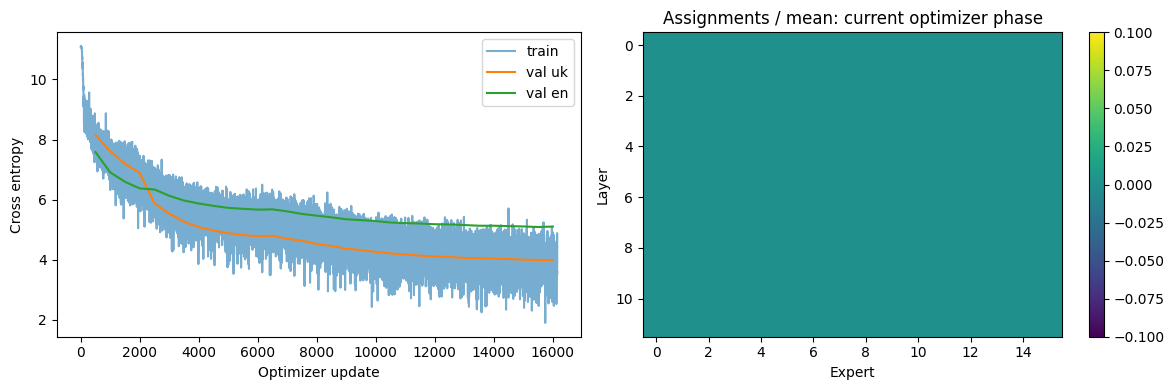

In [7]:
import matplotlib.pyplot as plt
records = [json.loads(line) for line in trainer.log_path.read_text().splitlines()]
fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].plot([r['step'] for r in records],[r['train_ce'] for r in records],label='train',alpha=.6)
for lang in ['uk','en']:
    validation = [r for r in records if f'val_ce_{lang}' in r]
    ax[0].plot([r['step'] for r in validation],[r[f'val_ce_{lang}'] for r in validation],label=f'val {lang}')
ax[0].set(xlabel='Optimizer update',ylabel='Cross entropy');ax[0].legend()
counts = trainer.routing_total.float().cpu()
image=ax[1].imshow((counts/counts.mean(-1,keepdim=True).clamp_min(1)).numpy(),aspect='auto')
ax[1].set(xlabel='Expert',ylabel='Layer',title='Assignments / mean: current optimizer phase')
fig.colorbar(image,ax=ax[1]);plt.tight_layout();plt.show()


## Продолжение текста

Сначала нужны языковые навыки; SFT/chat — отдельный следующий этап. Generation пересчитывает короткий
prefix, persistent decode cache пока нет. BOS не добавляем: текущий pretraining не обучал BOS в corpus.
Повторения не скрываются repetition penalty при оценке качества модели.


In [8]:
for prompt in ['Україна — це','The history of science']:
    ids=tokenizer.encode(prompt).ids
    tokens=torch.tensor([ids],device=trainer.device)
    with trainer.autocast():
        generated=trainer.model.generate(tokens,max_new_tokens=48,temperature=.8,top_k=40,
                                         context=SEQ_LEN,valid_vocab=tokenizer.get_vocab_size())
    print(tokenizer.decode(generated[0].tolist()));print()


Україна — це ім'я «Сема України» (1940 р.) та «Даси України» (1944 р.).

З 1957 року під час Першої світової війни він став обраний гетьманами Києва, працював у Галичині, став головою уряду

The history of science in New York City, in the United States. The story would not have been published in the UK.

In June 2010, the United States Congress issued an independent government to the Organization for Assembly.  In December 2009, an alliance



## Экспорт без дополнительной копии

Для inference используйте уже существующий weights.pt и tokenizer.json. Он не содержит optimizer.
По умолчанию не создаём model.pt, не архивируем полный run с дублированием весов.
Для полноценного exact resume вне текущего runtime скачайте local last.pt отдельно, если нужно.


In [ ]:
RELOAD_FOR_INFERENCE = False
if RELOAD_FOR_INFERENCE:
    del trainer;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
    payload=torch.load(weights_path,map_location='cpu',weights_only=True,mmap=True)
    restored=NextMoE(ModelConfig(**payload['model_config']))
    dtype=next(iter(payload['model'].values())).dtype
    restored=restored.to(dtype=dtype)
    restored.load_state_dict(payload['model'])
    restored=restored.to('cuda' if torch.cuda.is_available() else 'cpu').eval()
    del payload
DOWNLOAD_WEIGHTS = False
if DOWNLOAD_WEIGHTS:
    from google.colab import files
    files.download(str(weights_path))
    files.download(str(RUN_DIR/'tokenizer.json'))


Бенчмарк, щоб перевірити швидкість ГП

In [20]:
import urllib.request

url = (
    "https://raw.githubusercontent.com/FactorialD/next-moe/"
    "05c6881/scripts/colab_efficiency.py"
)
exec(urllib.request.urlopen(url).read().decode("utf-8"))

results = benchmark_batch_layout(trainer, units_per_hour=8.9)

BENCHMARK: microbatch=1, accumulation=4, block_checkpointing=True; updates will be rolled back.
{"step": 6010, "train_ce": 4.260631799697876, "router_aux": 1.044932246208191, "lr": 2.1550851010789113e-05, "tokens_seen": 9236480, "grad_norm": 1.161771297454834, "tokens_per_second_training_step": 1102.865434654798, "data_loading_seconds": 0.0021312899989425205, "unselected_expert_fraction_phase": 0.0, "max_expert_to_mean_load_phase": 1.6420599222183228, "unselected_expert_fraction_this_step": 0.0, "max_expert_to_mean_load": 2.43359375, "peak_allocated_GiB": 5.197104454040527, "peak_reserved_GiB": 5.732421875, "tokens_per_second_including_interval_overhead": 1114.704744308369}
{"microbatch": 1, "accumulation": 4, "checkpoint_blocks": true, "effective_tokens_per_update": 2048, "median_training_tokens_per_second": 1114.819341769366, "units_per_hour_assumed": 8.9, "training_tokens_per_unit": 450938.1607156986, "peak_allocated_GiB": 5.197104454040527, "peak_reserved_GiB": 5.732421875}
BENCHMA

In [24]:
#extend_token_budget(trainer, 30_000_000, ramp_updates=100)
trainer.run()

{"step": 7040, "train_ce": 5.650920867919922, "router_aux": 1.015140175819397, "lr": 5.1447680086312716e-05, "tokens_seen": 11345920, "grad_norm": 1.3134493827819824, "tokens_per_second_training_step": 6406.863653003531, "data_loading_seconds": 0.00016691000018909108, "unselected_expert_fraction_phase": 0.0, "max_expert_to_mean_load_phase": 1.6318739652633667, "unselected_expert_fraction_this_step": 0.0, "max_expert_to_mean_load": 1.953125, "peak_allocated_GiB": 7.390818119049072, "peak_reserved_GiB": 8.111328125, "tokens_per_second_including_interval_overhead": 6482.077849410474}
{"step": 7050, "train_ce": 4.867215156555176, "router_aux": 1.0164389610290527, "lr": 6.422359876991229e-05, "tokens_seen": 11366400, "grad_norm": 1.22157621383667, "tokens_per_second_training_step": 6308.483927621503, "data_loading_seconds": 0.00017614900025364477, "unselected_expert_fraction_phase": 0.0, "max_expert_to_mean_load_phase": 1.6316908597946167, "unselected_expert_fraction_this_step": 0.0, "max_e

{'val_ce_uk': 3.98923197388649,
 'val_ppl_uk': 54.01338973517164,
 'val_ce_en': 5.111127853393555,
 'val_ppl_en': 165.85731215606978}

Зберігаємо 2 етап в архів на гугл диску

In [9]:
from pathlib import Path
import shutil

archive = Path(
    "/content/drive/MyDrive/next-moe/checkpoint-30m-frozen"
)
archive.mkdir(parents=True, exist_ok=False)

for name in (
    "weights.pt",
    "model_config.json",
    "train_config.json",
    "source_hashes.json",
    "metrics.jsonl",
    "pip-freeze.txt",
):
    source = RUN_DIR / name
    if source.exists():
        shutil.copy2(source, archive / name)

shutil.copytree(RUN_DIR / "data-v2", archive / "data-v2")

size = sum(p.stat().st_size for p in archive.rglob("*") if p.is_file())
print("Архів:", archive)
print(f"Розмір: {size / 2**30:.2f} GiB")

Архів: /content/drive/MyDrive/next-moe/checkpoint-30m-frozen
Розмір: 0.61 GiB
